# 01 · EDA — Competencia crediticia
Objetivo: entender los datos antes de decidir limpieza, features y modelos.
Variable objetivo: `SeriousDlqin2yrs` (1 = dificultades financieras graves en 2 años). Métrica: AUC-ROC.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ks_2samp

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
train = pd.read_csv(ROOT / "data/raw/train.csv")
test = pd.read_csv(ROOT / "data/raw/test.csv")
TARGET, ID = "SeriousDlqin2yrs", "Id"
FEATS = [c for c in train.columns if c not in (TARGET, ID)]
LATE = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
]

## 1. Visión general

In [2]:
print("train:", train.shape, "| test:", test.shape)
print("filas duplicadas (sin Id):", train.drop(columns=ID).duplicated().sum())
print("Ids compartidos train/test:", len(set(train[ID]) & set(test[ID])))
rate = train[TARGET].mean()
print(f"Tasa positiva: {rate:.4f} ({train[TARGET].sum()} de {len(train)})")
train.dtypes.to_frame("dtype").join(train.nunique().rename("n_unique"))

train: (105000, 12) | test: (45000, 11)
filas duplicadas (sin Id): 339
Ids compartidos train/test: 0
Tasa positiva: 0.0668 (7018 de 105000)


,dtype,n_unique
Id,int64,105000
SeriousDlqin2yrs,int64,2
RevolvingUtilizationOfUnsecuredLines,float64,88528
age,int64,83
NumberOfTime30-59DaysPastDueNotWorse,int64,16
DebtRatio,float64,82380
MonthlyIncome,float64,12073
NumberOfOpenCreditLinesAndLoans,int64,57
NumberOfTimes90DaysLate,int64,18
NumberRealEstateLoansOrLines,int64,28


## 2. Valores faltantes

In [3]:
miss = pd.concat(
    [train[FEATS].isna().mean().rename("train"), test[FEATS].isna().mean().rename("test")],
    axis=1,
)
display(miss.round(4))
# ¿El faltante en ingreso es informativo?
train.groupby(train["MonthlyIncome"].isna())[TARGET].agg(["mean", "count"]).round(4)

,train,test
RevolvingUtilizationOfUnsecuredLines,0.0000,0.0000
age,0.0000,0.0000
NumberOfTime30-59DaysPastDueNotWorse,0.0000,0.0000
DebtRatio,0.0000,0.0000
MonthlyIncome,0.1984,0.1978
NumberOfOpenCreditLinesAndLoans,0.0000,0.0000
NumberOfTimes90DaysLate,0.0000,0.0000
NumberRealEstateLoansOrLines,0.0000,0.0000
NumberOfTime60-89DaysPastDueNotWorse,0.0000,0.0000
NumberOfDependents,0.0264,0.0256


,mean,count
MonthlyIncome,,
False,0.0695,84172
True,0.0561,20828


## 3. Anomalías: centinelas, edad y colas

In [4]:
for c in LATE:
    print(c, train[c].value_counts().sort_index().tail(6).to_dict())
sent = (train[LATE] >= 96).any(axis=1)
print("\nFilas con código 96/98:", sent.sum())
print("Tasa de impago con centinela:", round(train.loc[sent, TARGET].mean(), 4),
      "| sin centinela:", round(train.loc[~sent, TARGET].mean(), 4))
print("age < 18:", (train["age"] < 18).sum(), "| age > 90:", (train["age"] > 90).sum())
train[FEATS].quantile([0.01, 0.5, 0.9, 0.99, 0.999, 1.0]).T

NumberOfTime30-59DaysPastDueNotWorse {10: 4, 11: 1, 12: 1, 13: 1, 96: 3, 98: 194}
NumberOfTimes90DaysLate {12: 1, 13: 3, 14: 2, 15: 2, 96: 3, 98: 194}
NumberOfTime60-89DaysPastDueNotWorse {7: 8, 8: 1, 9: 1, 11: 1, 96: 3, 98: 194}

Filas con código 96/98: 197
Tasa de impago con centinela: 0.5685 | sin centinela: 0.0659
age < 18: 1 | age > 90: 336


,0.010,0.500,0.900,0.990,0.999,1.000
RevolvingUtilizationOfUnsecuredLines,0.0,0.154257,0.981457,1.092203,1577.043,50708.0
age,24.0,52.000000,72.000000,87.000000,94.000,103.0
NumberOfTime30-59DaysPastDueNotWorse,0.0,0.000000,1.000000,4.000000,98.000,98.0
DebtRatio,0.0,0.366414,1267.000000,5011.010000,10930.265,329664.0
MonthlyIncome,0.0,5400.000000,11615.900000,25000.000000,75000.000,3008750.0
NumberOfOpenCreditLinesAndLoans,0.0,8.000000,15.000000,24.000000,34.000,58.0
NumberOfTimes90DaysLate,0.0,0.000000,0.000000,3.000000,98.000,98.0
NumberRealEstateLoansOrLines,0.0,1.000000,2.000000,4.000000,9.000,54.0
NumberOfTime60-89DaysPastDueNotWorse,0.0,0.000000,0.000000,2.000000,98.000,98.0
NumberOfDependents,0.0,0.000000,2.000000,4.000000,6.000,13.0


## 4. Distribuciones (recortadas al percentil 99 para poder verlas)

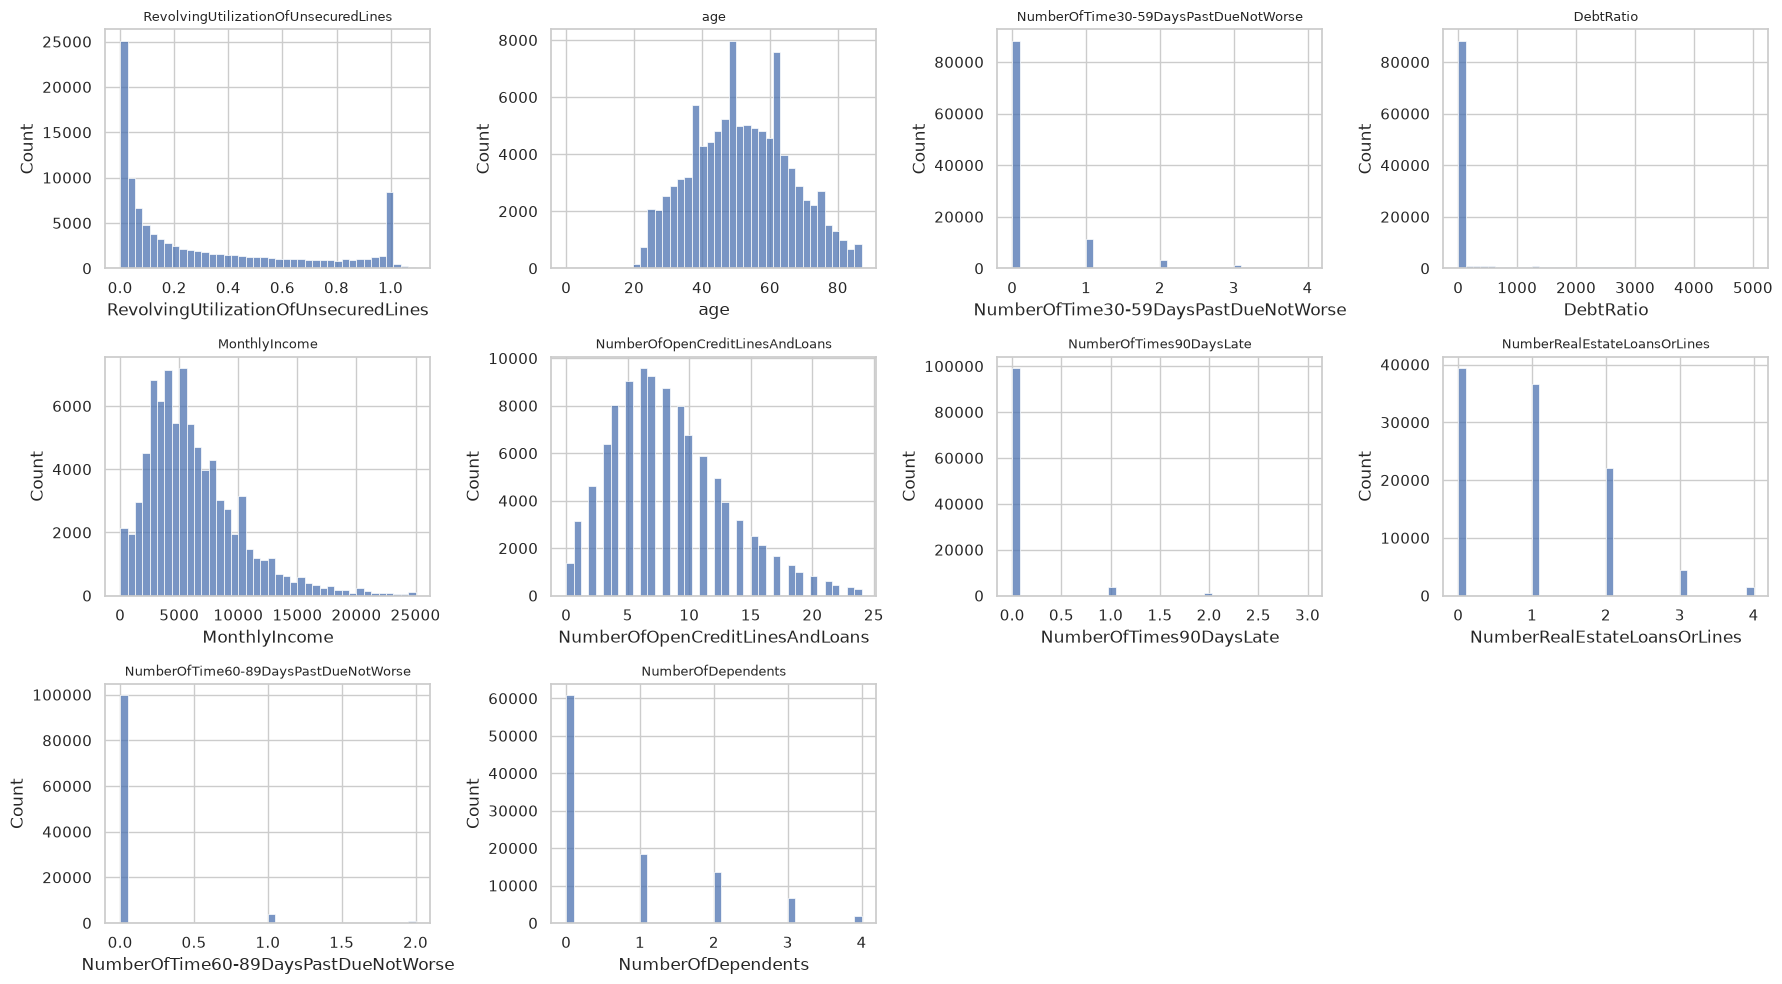

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, c in zip(axes.ravel(), FEATS):
    s = train[c].dropna()
    s = s[s <= s.quantile(0.99)]
    sns.histplot(s, bins=40, ax=ax)
    ax.set_title(c, fontsize=9)
for ax in axes.ravel()[len(FEATS):]:
    ax.axis("off")
plt.tight_layout()

## 5. Tasa de impago por variable

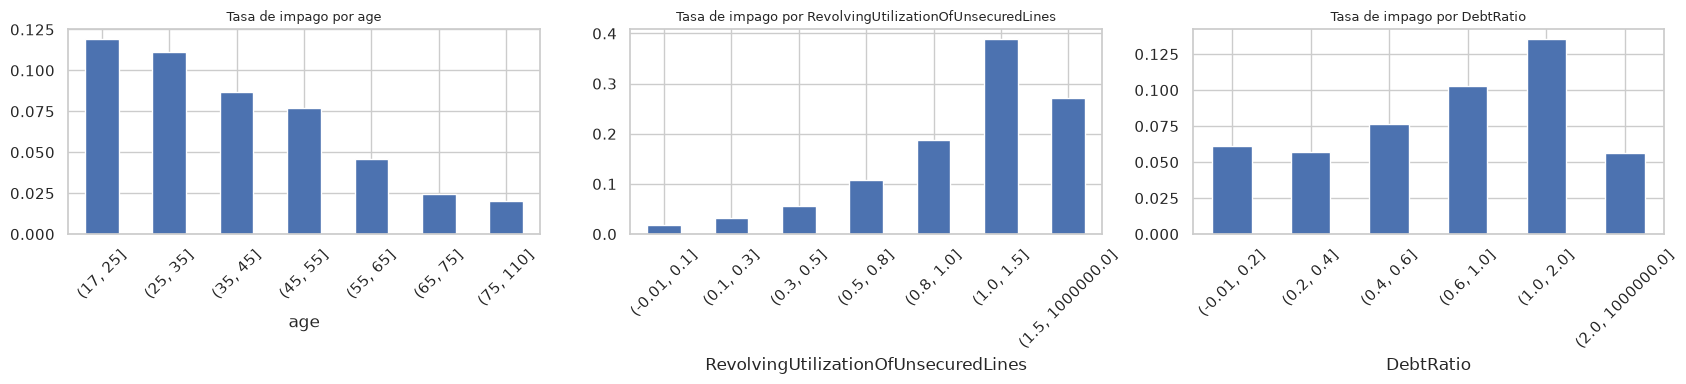

In [6]:
specs = [
    ("age", [17, 25, 35, 45, 55, 65, 75, 110]),
    ("RevolvingUtilizationOfUnsecuredLines", [-0.01, 0.1, 0.3, 0.5, 0.8, 1, 1.5, 1e6]),
    ("DebtRatio", [-0.01, 0.2, 0.4, 0.6, 1, 2, 1e6]),
]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (col, bins) in zip(axes, specs):
    g = train.groupby(pd.cut(train[col], bins), observed=True)[TARGET].mean()
    g.plot(kind="bar", ax=ax)
    ax.set_title(f"Tasa de impago por {col}", fontsize=9)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

In [7]:
for c in LATE:
    s = train[c].where(train[c] < 96).clip(upper=6)
    print(c)
    print(train.groupby(s)[TARGET].agg(["mean", "count"]).round(3), "\n")

NumberOfTime30-59DaysPastDueNotWorse
                                       mean  count
NumberOfTime30-59DaysPastDueNotWorse              
0.0                                   0.040  88251
1.0                                   0.150  11191
2.0                                   0.258   3169
3.0                                   0.335   1253
4.0                                   0.444    516
5.0                                   0.464    250
6.0                                   0.480    173 

NumberOfTimes90DaysLate
                          mean  count
NumberOfTimes90DaysLate              
0.0                      0.046  99157
1.0                      0.337   3667
2.0                      0.499   1079
3.0                      0.566    468
4.0                      0.632    209
5.0                      0.690     87
6.0                      0.662    136 

NumberOfTime60-89DaysPastDueNotWorse
                                       mean  count
NumberOfTime60-89DaysPastDueNotWorse          

## 6. Correlación (Spearman) con el objetivo

age                                    -0.119
MonthlyIncome                          -0.068
NumberOfOpenCreditLinesAndLoans        -0.039
NumberRealEstateLoansOrLines           -0.036
DebtRatio                               0.019
NumberOfDependents                      0.046
RevolvingUtilizationOfUnsecuredLines    0.241
NumberOfTime30-59DaysPastDueNotWorse    0.254
NumberOfTime60-89DaysPastDueNotWorse    0.275
NumberOfTimes90DaysLate                 0.342
Name: SeriousDlqin2yrs, dtype: float64

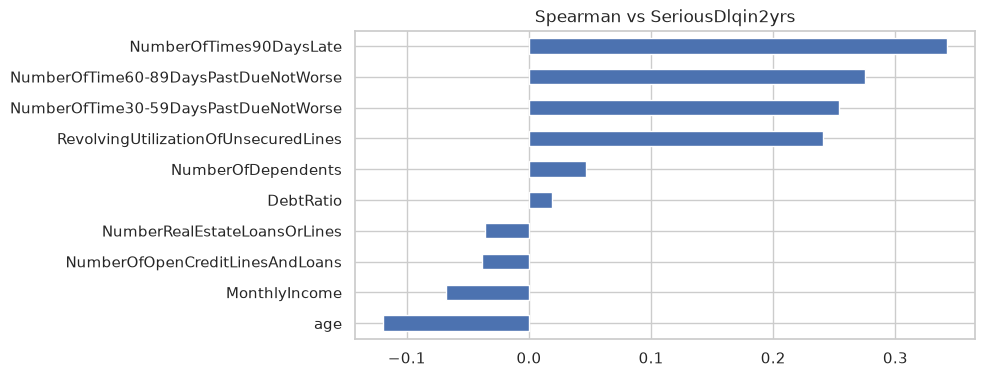

In [8]:
sp = train[FEATS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values()
sp.plot(kind="barh", figsize=(8, 4), title="Spearman vs SeriousDlqin2yrs")
sp.round(3)

## 7. Deriva entre train y test (KS)
Un KS alto significa que la variable se distribuye distinto en train y test.

In [9]:
rows = []
for c in FEATS:
    r = ks_2samp(train[c].dropna(), test[c].dropna())
    rows.append((c, r.statistic, r.pvalue))
pd.DataFrame(rows, columns=["feature", "KS", "p_value"]).sort_values("KS", ascending=False).round(4)

,feature,KS,p_value
4,MonthlyIncome,0.0053,0.4727
3,DebtRatio,0.0041,0.6637
1,age,0.0039,0.7100
0,RevolvingUtilizationOfUnsecuredLines,0.0035,0.8268
5,NumberOfOpenCreditLinesAndLoans,0.0031,0.9150
7,NumberRealEstateLoansOrLines,0.0019,0.9999
2,NumberOfTime30-59DaysPastDueNotWorse,0.0014,1.0000
9,NumberOfDependents,0.0012,1.0000
6,NumberOfTimes90DaysLate,0.0006,1.0000
8,NumberOfTime60-89DaysPastDueNotWorse,0.0006,1.0000


## 8. Relaciones entre variables
Dispersión con densidades marginales por clase (azul = 0, rojo = 1). Muestra de 30,000 filas.
Transformaciones solo para visualizar: centinelas y age < 18 a NaN, topes y logaritmos.

In [10]:
d = train.copy()
d[LATE] = d[LATE].where(d[LATE] < 96)
d["age"] = d["age"].where(d["age"] >= 18)
d["util_clip"] = d["RevolvingUtilizationOfUnsecuredLines"].clip(upper=2)
d["log_debt_ratio"] = np.log1p(d["DebtRatio"].clip(upper=1e5))
d["log_income"] = np.log10(d["MonthlyIncome"].clip(lower=1))
d["total_late"] = d[LATE].sum(axis=1, min_count=1)
PAL = {0: "#1f77b4", 1: "#d62728"}


def joint(x, y, n=30000, **kw):
    s = d.dropna(subset=[x, y])
    s = s.sample(min(n, len(s)), random_state=42)
    g = sns.jointplot(
        data=s, x=x, y=y, hue=TARGET, palette=PAL, kind="scatter", height=7,
        s=12, alpha=0.5, marginal_kws=dict(common_norm=False, fill=True), **kw,
    )
    g.figure.suptitle(f"{x} vs {y}", y=1.02)
    return g

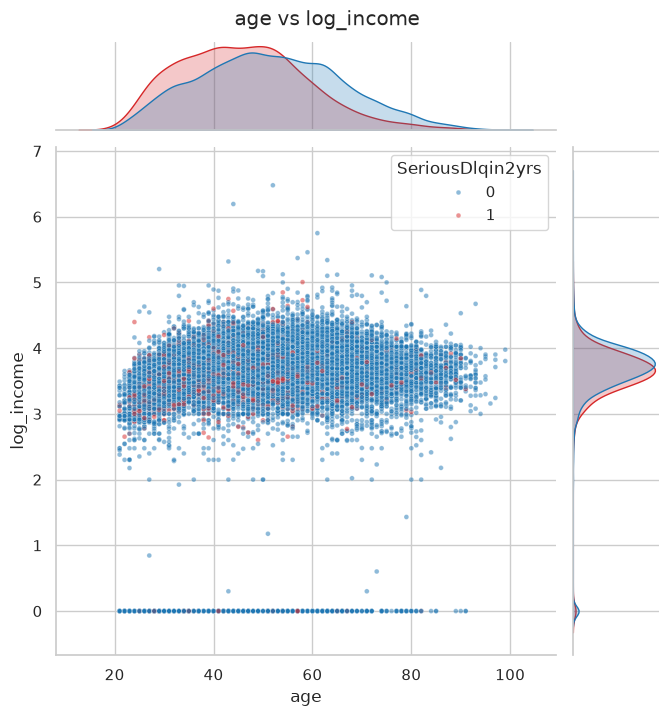

In [11]:
joint("age", "log_income")

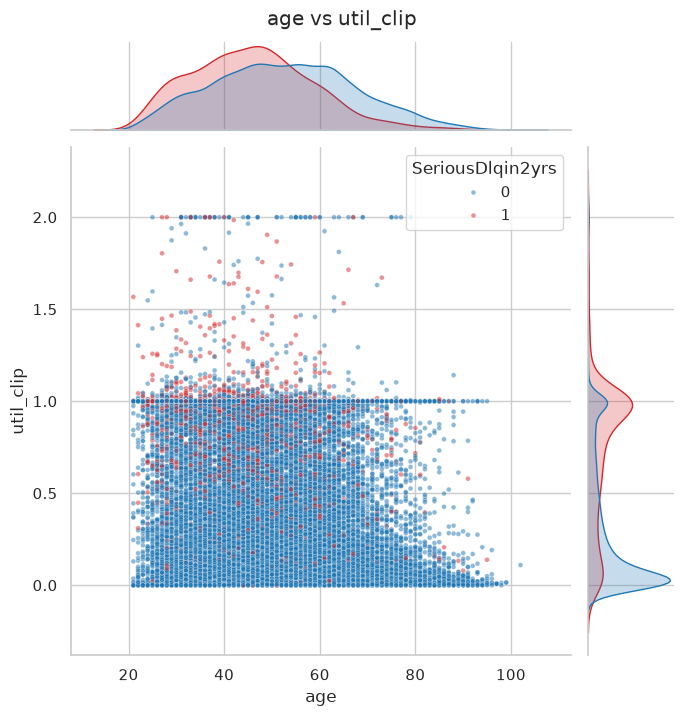

In [12]:
joint("age", "util_clip")

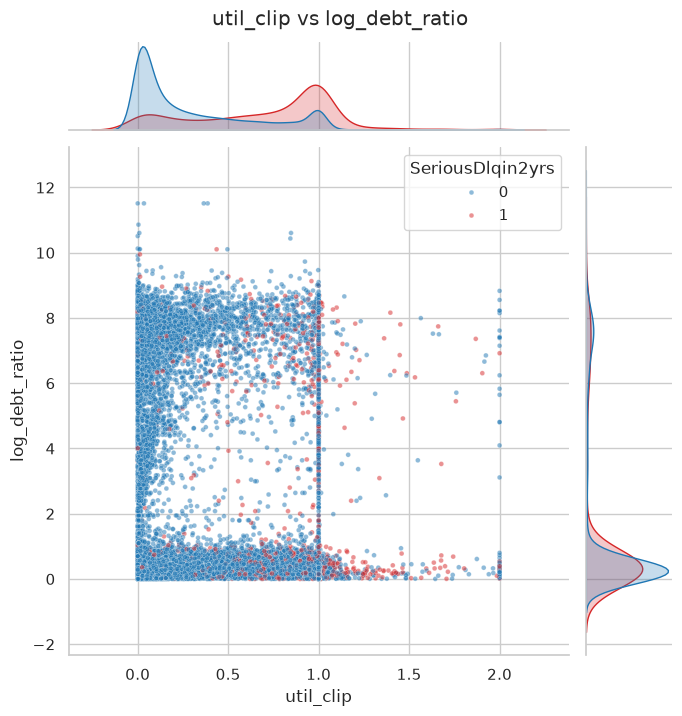

In [13]:
joint("util_clip", "log_debt_ratio")

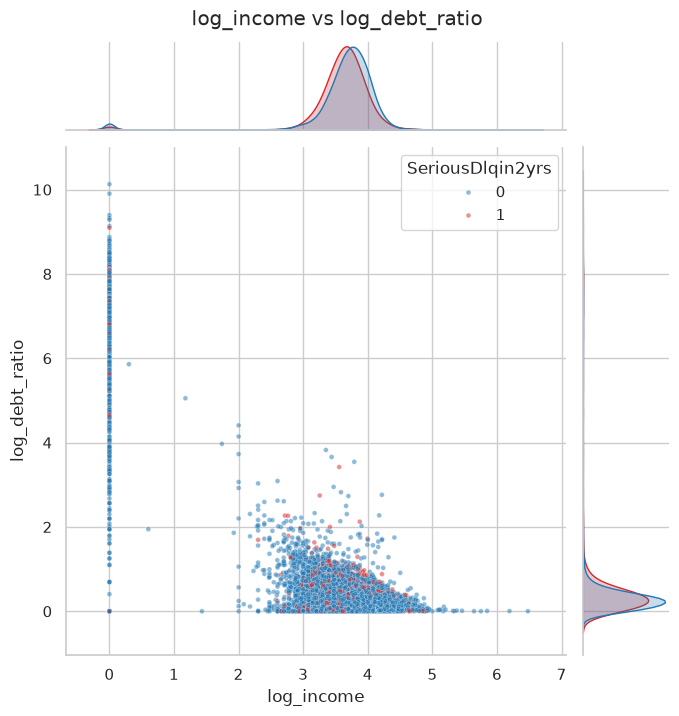

In [14]:
joint("log_income", "log_debt_ratio")

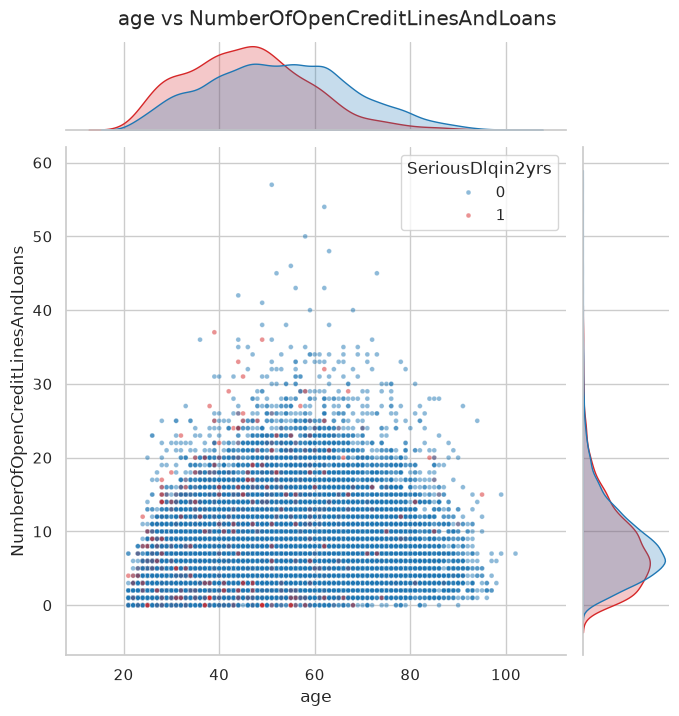

In [15]:
joint("age", "NumberOfOpenCreditLinesAndLoans")

### DebtRatio extremo e ingreso faltante
Hipótesis: cuando falta el ingreso, DebtRatio parece ser un monto y no una razón.

In [16]:
d["income_missing"] = d["MonthlyIncome"].isna()
display(d.groupby("income_missing")["DebtRatio"].describe(percentiles=[0.5, 0.9, 0.99]).round(2))
print("Proporción con DebtRatio > 1:",
      d.groupby("income_missing")["DebtRatio"].apply(lambda s: (s > 1).mean()).round(3).to_dict())

,count,mean,std,min,50%,90%,99%,max
income_missing,,,,,,,,
False,84172.0,25.64,368.19,0.0,0.3,0.77,651.00,61106.5
True,20828.0,1702.83,4928.66,0.0,1158.0,3795.00,8198.19,329664.0


Proporción con DebtRatio > 1: {False: 0.061, True: 0.938}


### Correlación entre variables (Spearman)

<Axes: >

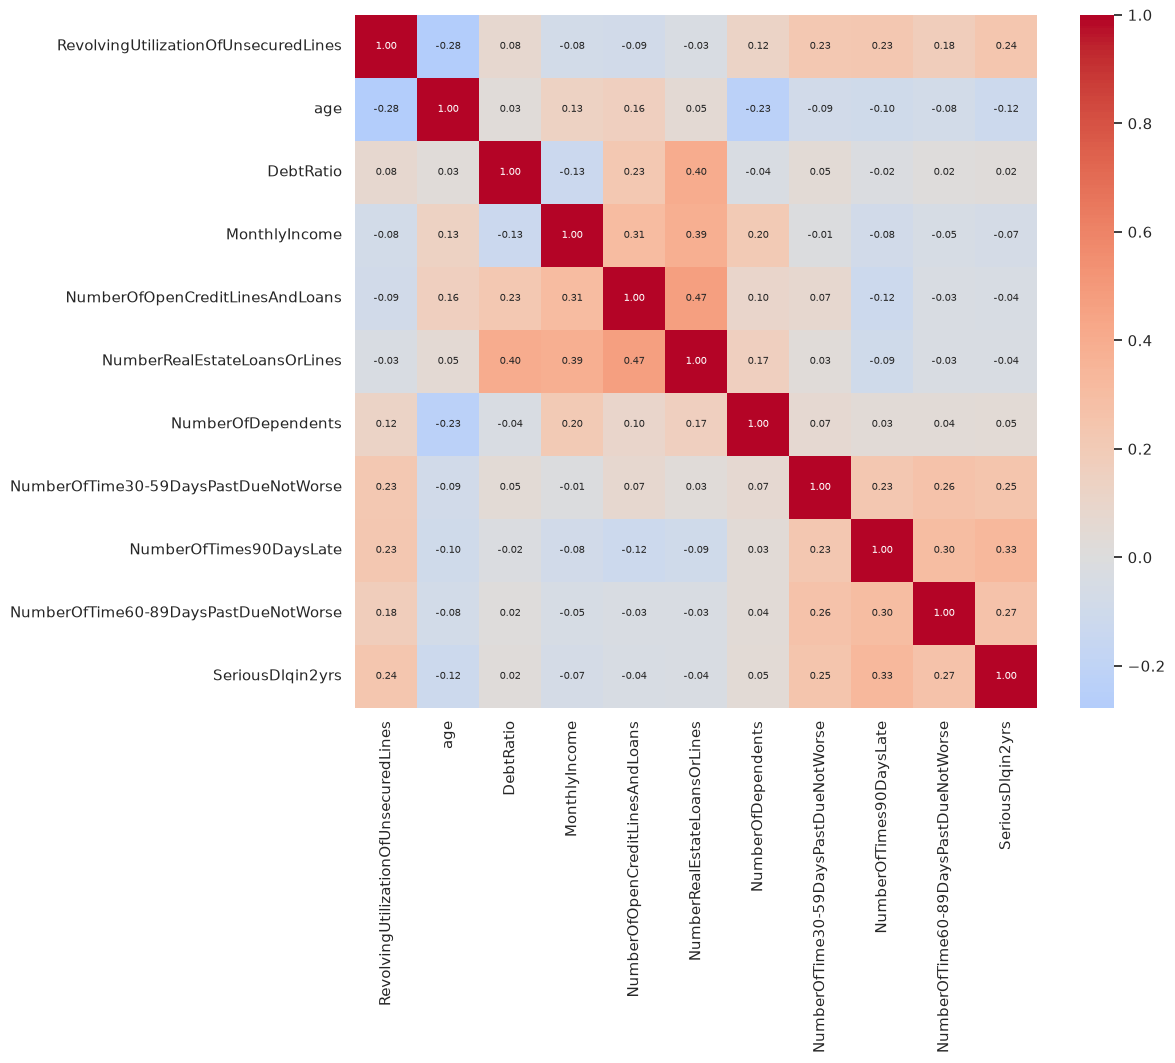

In [17]:
num = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
       "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines",
       "NumberOfDependents"] + LATE + [TARGET]
plt.figure(figsize=(11, 9))
sns.heatmap(d[num].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, annot_kws={"size": 7})

### Tasa de impago: edad × utilización

<Axes: xlabel='util_clip', ylabel='age'>

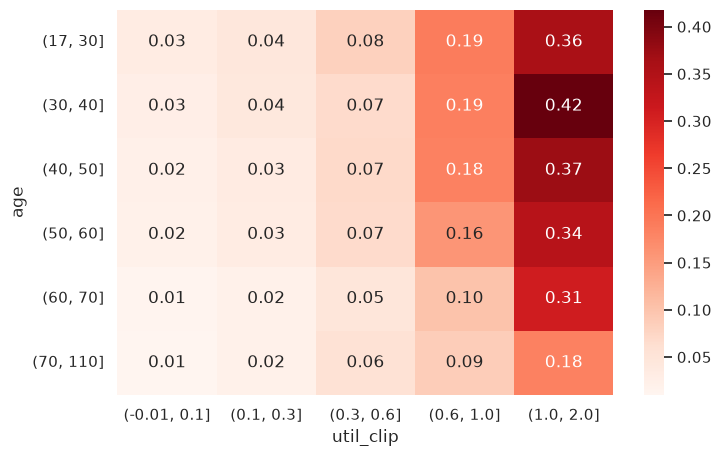

In [18]:
pt = d.pivot_table(
    index=pd.cut(d["age"], [17, 30, 40, 50, 60, 70, 110]),
    columns=pd.cut(d["util_clip"], [-0.01, 0.1, 0.3, 0.6, 1, 2]),
    values=TARGET, aggfunc="mean", observed=True,
)
plt.figure(figsize=(8, 5))
sns.heatmap(pt, annot=True, fmt=".2f", cmap="Reds")

### Ingreso igual a cero y DebtRatio
Verifica si las filas con ingreso 0 explican el DebtRatio alto con ingreso presente.

In [ ]:
inc0 = d["MonthlyIncome"] == 0
print("Filas con ingreso == 0:", inc0.sum(), "| tasa de impago:", round(d.loc[inc0, TARGET].mean(), 4))
print("DebtRatio mediano con ingreso == 0:", d.loc[inc0, "DebtRatio"].median())
print("Filas con ingreso presente > 0 y DebtRatio > 1:",
      ((d["MonthlyIncome"] > 0) & (d["DebtRatio"] > 1)).sum())

## 9. Hallazgos y decisiones (EDA, versión 1)
**Datos generales (secciones 1 a 7)**
- Clase positiva 6.68%: desbalance moderado. CV estratificada y AUC como métrica.
- Faltantes: MonthlyIncome 19.8% (train) y 19.8% (test); NumberOfDependents 2.6% y 2.6%.
  Impago con ingreso faltante 5.6% vs 7.0% con ingreso: el faltante tiene algo de señal.
- Centinelas 96/98: 197 filas (194 con 98, 3 con 96), las mismas en las tres columnas de atrasos.
  Impago 56.9% con centinela vs 6.6% sin centinela: señal muy fuerte. No eliminar filas.
- age: 1 fila menor de 18 (inválida); 336 filas mayores de 90 (válidas, revisar).
- Colas: Utilization p99 = 1.09 pero máximo 50,708; DebtRatio mediana 0.37, p90 1,267, máximo 329,664;
  MonthlyIncome máximo 3,008,750 y con ceros. Topes fijos y logaritmos; no eliminar filas.
- Deriva train/test: KS máximo 0.0053 y p > 0.47. Sin evidencia de deriva; el CV local debería
  reflejar el leaderboard.

**Relaciones entre variables (sección 8)**
- Mayor señal (Spearman con el objetivo): 90 días de atraso 0.33, 60-89 días 0.27, 30-59 días 0.25,
  utilización 0.24, edad -0.12, ingreso -0.07. El resto cerca de 0: dependientes 0.05,
  líneas abiertas -0.04, inmuebles -0.04, DebtRatio 0.02.
- Los tres conteos de atrasos correlacionan entre sí (0.23 a 0.30): candidatos a agregarse.
- Utilización: la clase 1 se concentra en utilización cercana a 1 y la clase 0 cerca de 0.
  Tasa de impago por tramo: 1-4% (hasta 0.3), 5-8% (0.3 a 0.6), 9-19% (0.6 a 1), 18-42% (mayor a 1).
- Edad × utilización: a igual utilización, los jóvenes tienen más impago; el máximo es 42% en 30 a 40 años
  con utilización > 1 y el mínimo 18% en mayores de 70. Hay interacción.
- DebtRatio no es comparable entre filas: con ingreso faltante (n = 20,828) mediana 1,158 y p99 8,198
  (se comporta como un monto); con ingreso presente mediana 0.30 y p90 0.77, pero p99 651 y máximo 61,106.
  Los valores altos con ingreso presente se ubican en ingreso = 0 (gráfico log_income vs log_debt_ratio).
  Por eso su correlación con el objetivo es solo 0.02. Confirmar con la celda de ingreso = 0.
- Ingreso = 0 forma un grupo aparte (la línea en log_income = 0).
- Líneas abiertas, inmuebles, ingreso y DebtRatio forman un bloque correlacionado (0.23 a 0.47)
  con poca señal directa; posible aporte por interacciones.
- Edad y líneas abiertas se distribuyen de forma parecida en ambas clases: señal baja.

**Propuesta de features (a validar con el equipo)**
1. Centinelas 96/98 a NaN + bandera late_sentinel.
2. Banderas income_missing, income_zero y dependents_missing.
3. debt_ratio_valid: DebtRatio solo si el ingreso está presente y es mayor a 0; si no, NaN.
4. debt_amount unificado: DebtRatio si falta el ingreso; DebtRatio x ingreso si está presente.
   (Corrige la versión anterior, que multiplicaba siempre.)
5. Atrasos agregados: total, alguno y máximo.
6. Utilización: tope en 2, logaritmo y bandera de utilización > 1.
7. Edad a NaN si es menor de 18; para el baseline lineal, edad en tramos o interacción con utilización.

**Decisiones abiertas**
- Estrategia de validación: StratifiedKFold repetida; baseline logreg vs LightGBM.
- Tratamiento del ingreso 0: valor válido o faltante encubierto.